# CIFAR-10 Classification — Fast Transfer Learning
**ICE 4112 | AI Lab | BAUET**  
**Dataset:** CIFAR-10 | **Pretrained model:** MobileNetV2

Fast demo: 3,000 training, 600 validation and 1,000 test images; 2 epochs. The test metrics describe this subset, not the full CIFAR-10 benchmark. Change the sample sizes and epochs for a more thorough experiment.

In [1]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
(x,y),(xt,yt) = keras.datasets.cifar10.load_data()
y,yt = y.ravel(),yt.ravel()

# Small, disjoint subsets for a quick quiz demonstration
rng = np.random.default_rng(42)
idx = rng.permutation(len(x))
tr,va = idx[:3000],idx[3000:3600]
ti = rng.permutation(len(xt))[:1000]

def ds(images,labels,shuffle=False):
    d = tf.data.Dataset.from_tensor_slices((images,labels))
    if shuffle: d = d.shuffle(len(images),seed=42)
    d = d.map(lambda a,b: (keras.applications.mobilenet_v2.preprocess_input(
        tf.image.resize(tf.cast(a,tf.float32),(96,96))), b),
        num_parallel_calls=tf.data.AUTOTUNE)
    return d.batch(64).prefetch(tf.data.AUTOTUNE)

train,val,test = ds(x[tr],y[tr],True),ds(x[va],y[va]),ds(xt[ti],yt[ti])
print('Train:',len(tr),'Validation:',len(va),'Test:',len(ti))

Train: 3000 Validation: 600 Test: 1000


In [2]:
# ImageNet-pretrained transfer learning; train only a small classifier head
base = keras.applications.MobileNetV2(input_shape=(96,96,3),include_top=False,weights='imagenet')
base.trainable = False
model = keras.Sequential([
    keras.Input((96,96,3)),
    keras.layers.RandomFlip('horizontal'),
    base,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10,activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
h = model.fit(train,validation_data=val,epochs=2,
              callbacks=[keras.callbacks.EarlyStopping(patience=1,restore_best_weights=True)],
              verbose=1)

Epoch 1/2


c:\Users\STUDENT\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.4147 - loss: 1.8899 - val_accuracy: 0.7317 - val_loss: 0.7910
Epoch 2/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.7057 - loss: 0.8756 - val_accuracy: 0.7867 - val_loss: 0.6126


              precision    recall  f1-score   support

    airplane      0.791     0.813     0.802       107
  automobile      0.933     0.907     0.920       108
        bird      0.596     0.694     0.641        85
         cat      0.592     0.634     0.612       112
        deer      0.739     0.630     0.680       108
         dog      0.819     0.602     0.694        98
        frog      0.903     0.843     0.872       121
       horse      0.663     0.792     0.722        72
        ship      0.848     0.857     0.852        91
       truck      0.829     0.939     0.880        98

    accuracy                          0.771      1000
   macro avg      0.771     0.771     0.768      1000
weighted avg      0.778     0.771     0.771      1000

Accuracy: 0.771


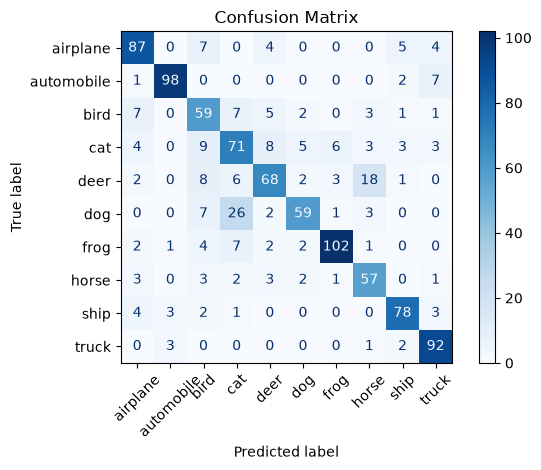

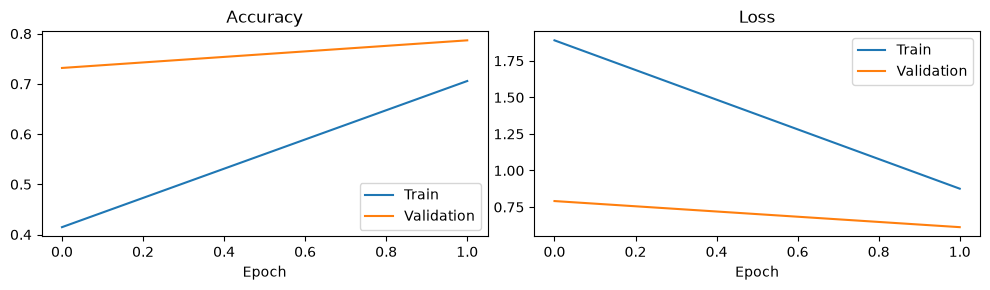

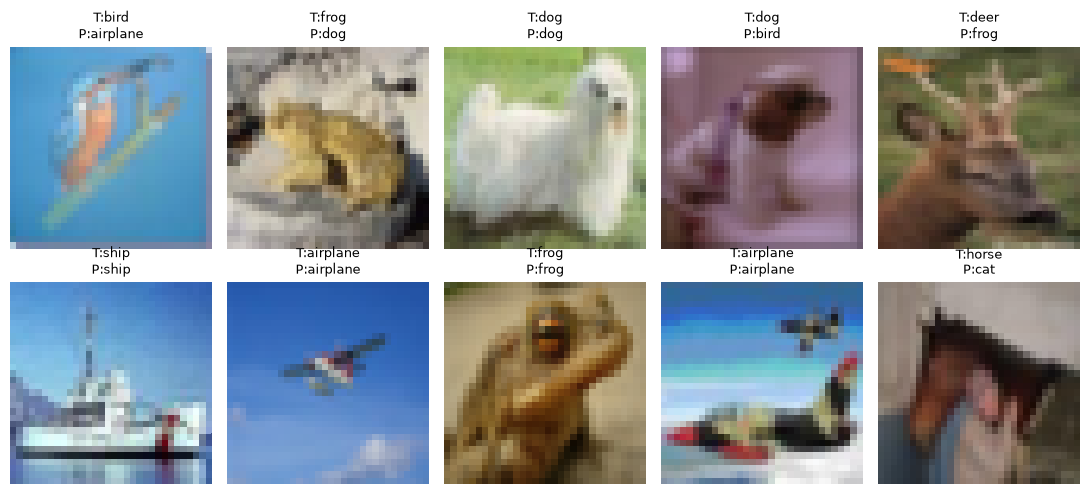

In [3]:
# Evaluation and visualizations
pred = model.predict(test,verbose=0).argmax(axis=1)
true = yt[ti]
print(classification_report(true,pred,labels=range(10),target_names=names,
                            digits=3,zero_division=0))
print('Accuracy:',round(np.mean(pred==true),4))
ConfusionMatrixDisplay(confusion_matrix(true,pred,labels=range(10)),
                       display_labels=names).plot(xticks_rotation=45,cmap='Blues')
plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

fig,ax=plt.subplots(1,2,figsize=(10,3))
for a,key in zip(ax,['accuracy','loss']):
    a.plot(h.history[key],label='Train')
    a.plot(h.history['val_'+key],label='Validation')
    a.set_title(key.title());a.set_xlabel('Epoch');a.legend()
plt.tight_layout();plt.show()

fig,ax=plt.subplots(2,5,figsize=(11,5))
for i,a in enumerate(ax.flat):
    a.imshow(xt[ti[i]]);a.set_title(f'T:{names[true[i]]}\nP:{names[pred[i]]}',fontsize=9)
    a.axis('off')
plt.tight_layout();plt.show()

## Result Analysis
The classification report prints **accuracy, precision, recall and F1-score**. The confusion matrix shows class-level errors. Compare the training and validation curves to assess potential overfitting. Dropout, augmentation and the frozen pretrained backbone help reduce overfitting. Results may be lower than full-dataset training because this fast demonstration uses only a small subset and two epochs.

**Observation:** After running, record the actual accuracy and the classes most frequently confused. Do not claim a benchmark score from this subset.

**References:** Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*; Sandler et al. (2018), *MobileNetV2: Inverted Residuals and Linear Bottlenecks*.